In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'FLRY3.SA'

In [13]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [14]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[FLRY3.SA] Cache existente cobre de 2020-01-02 a 2025-06-16.
[FLRY3.SA] Cache cobre período solicitado (2022-12-29 a 2025-06-16).
[FLRY3.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211229_20250617.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-16.
[^BVSP] Cache cobre período solicitado (2022-12-29 a 2025-06-16).
[^BVSP] Retornando 613 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,...,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,
2025-06-03,12.80,13.29,12.78,13.04,2432700,0.017161,0.010548,60.689509,0.118126,0.115089,...,12.894,12.7460,14.75,0.26,5.6694,136787.00000,137672.0000,136175.00000,137546.000000,9696700
2025-06-04,13.23,13.30,13.04,13.06,2257900,0.001534,0.006307,61.141966,0.130042,0.118079,...,12.934,12.7575,14.75,0.26,5.6332,137547.00000,138797.0000,136695.00000,137002.000000,10199100
2025-06-05,13.10,13.16,12.96,13.00,3712100,-0.004594,0.006829,58.949912,0.133108,0.121085,...,12.954,12.7485,14.75,0.26,5.5969,137003.00000,137451.0000,136031.00000,136236.000000,9484500
2025-06-06,13.07,13.20,12.98,13.07,2844500,0.005385,0.006581,60.719278,0.139578,0.124784,...,12.998,12.7790,14.75,0.26,5.5947,136236.00000,136890.0000,135601.00000,136102.000000,9119300
2025-06-09,13.06,13.18,12.80,12.97,2233100,-0.007651,0.007450,56.943277,0.135080,0.126843,...,13.028,12.7950,14.75,0.26,5.5760,136102.00000,136106.0000,134119.00000,135699.000000,7763800
2025-06-10,13.05,13.15,12.73,12.81,2600300,-0.012336,0.008482,51.432075,0.117252,0.124925,...,12.982,12.7910,14.75,0.26,5.5557,135716.00000,137369.0000,135716.00000,136436.000000,8186500
2025-06-11,12.75,12.98,12.72,12.77,1537900,-0.003123,0.008117,50.125931,0.098758,0.119691,...,12.924,12.7960,14.75,0.26,5.5390,136443.00000,137531.0000,135628.00000,137128.000000,8767100
2025-06-12,12.70,12.98,12.70,12.92,2437900,0.011746,0.008978,54.765155,0.095108,0.114775,...,12.908,12.8095,14.75,0.26,5.5388,137127.00000,137931.0000,136175.00000,137800.000000,7124600
2025-06-13,12.86,13.12,12.72,13.02,2528800,0.007740,0.009144,57.596962,0.099142,0.111648,...,12.898,12.8330,14.75,0.26,5.5652,137800.00000,137800.0000,136586.00000,137213.000000,8628300


## Verificação da volatilidade recente

In [15]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-03,0.350744,0.026898,0.510000,0.039110
2025-06-04,0.344262,0.026360,0.260000,0.019908
2025-06-05,0.333958,0.025689,0.200000,0.015385
2025-06-06,0.325818,0.024929,0.220000,0.016832
2025-06-09,0.329688,0.025419,0.380000,0.029298
2025-06-10,0.336139,0.026240,0.420000,0.032787
2025-06-11,0.330700,0.025897,0.259999,0.020360
2025-06-12,0.327079,0.025316,0.280000,0.021672
2025-06-13,0.332287,0.025521,0.400000,0.030722


In [16]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.51%
Valorização sugerida: 3.77%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [17]:
valorizacao = 0.04
DIAS_FUTURO = 7  # dias futuros para buscar a valorização

In [18]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)

In [19]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.772277
1.0    0.227723
Name: proportion, dtype: float64

In [20]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

Linha(s) removida(s) por NaN: 20


In [21]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=130,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'
                                        )

modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo.fit(X_train.values, y_train.values)



tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)


AUC no treino: 0.603
AUC na validação: 0.681
Diferença AUC (Treino - Validação): -0.078
PR AUC no treino: 0.403
PR AUC na validação: 0.521
Diferença PR AUC (Treino - Validação): -0.118


(np.float64(0.6029729503036123),
 np.float64(0.6809264317057596),
 np.float64(-0.0779534814021473),
 np.float64(0.40349461734720016),
 np.float64(0.5210724869114209))

Avaliar e logar modelo
MLflow Run ID: 9396c87e052d40b98cb722c801cccb66 para FLRY3.SA_15dias_x_0.04val_7dias_alvo
AUC no treino: 0.699
AUC na validação: 0.536

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.603
  Precisão média (em 360 janelas com previsão positiva): 0.272
  Recall médio: 0.462

Threshold Ideal Selecionado: 0.61
  Precisão Média Esperada: 42.57%
  Recall Médio Esperado: 24.99%
  Janelas Usadas para Precisão: 261.0

Threshold ideal baseado em recall mínimo: 0.61

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.377
Recall médio: 0.954
Sinais de compra presentes na vallidação: 26.0
Sinais de compra previstos na validação: 75
Modelo FLRY3.SA_15dias_x_0.04val_7dias_alvo salvo na run 9396c87e052d40b98cb722c801cccb66


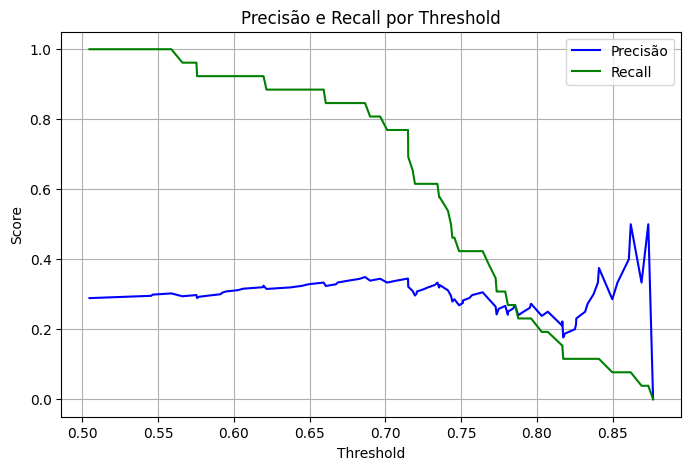

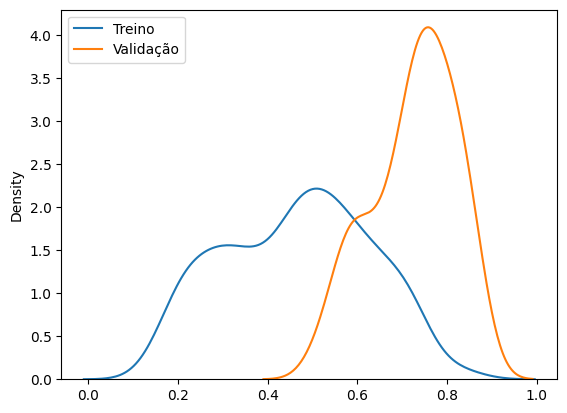

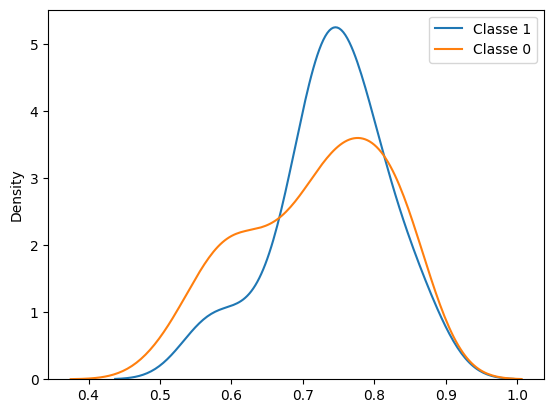

In [25]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [22]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': 'balanced'
        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    modelo_final_calibrado = CalibratedClassifierCV(
        modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
        method=metodo_calibracao,
        cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
    )

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado

In [23]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (482 amostras):
  - Treino Base LGBM: 386 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 92, number of negative: 294
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000665 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 8524
[LightGBM] [Info] Number of data points in the train set: 386, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


AUC no treino: 0.899
AUC na validação: 0.580
Diferença AUC (Treino - Validação): 0.319
PROVÁVEL OVERFITTING
PR AUC no treino: 0.718
PR AUC na validação: 0.405
Diferença PR AUC (Treino - Validação): 0.313


(np.float64(0.8992582287602903),
 np.float64(0.5802729302479173),
 np.float64(0.318985298512373),
 np.float64(0.7175242977064881),
 np.float64(0.40484273050074604))

Avaliar e logar modelo
MLflow Run ID: e1602e54f7c34c9a9999c1f186f19833 para FLRY3.SA_15dias_x_0.04val_7dias_alvo
AUC no treino: 0.912
AUC na validação: 0.540

--- Conjunto de Treino --- Janelas


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Threshold 0.50 - AUC: 0.899
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000
Nenhum threshold atendeu ao recall mínimo de 0.10. Seguindo com 0.5

Threshold ideal baseado em recall mínimo: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 26.0
Sinais de compra previstos na validação: 0


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Modelo FLRY3.SA_15dias_x_0.04val_7dias_alvo salvo na run e1602e54f7c34c9a9999c1f186f19833


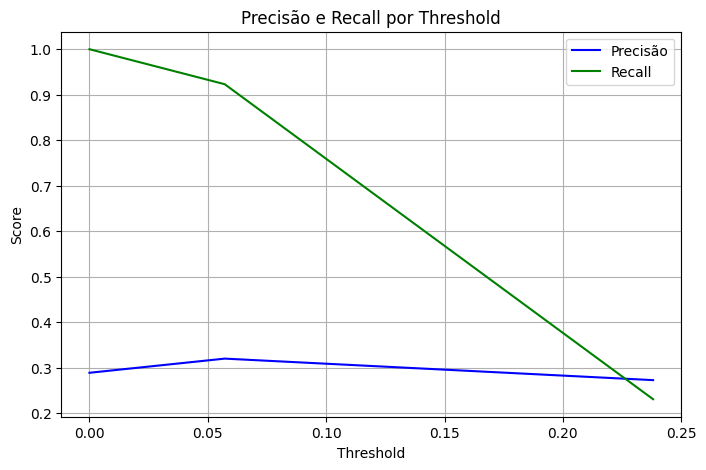

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


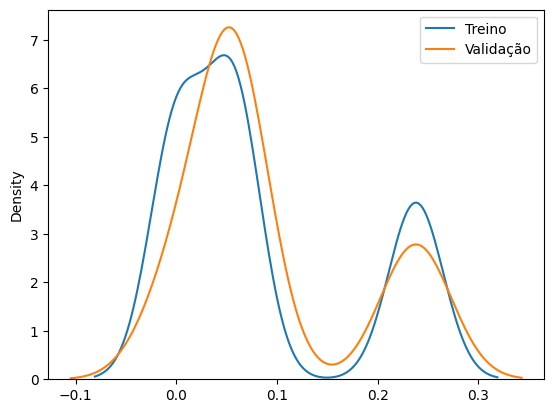

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


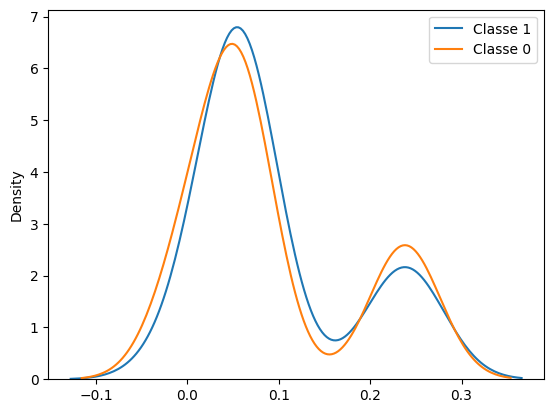

In [24]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [ ]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='isotonic', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=3,
                                                        min_samples_leaf=130,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

In [ ]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)


Avaliar e logar modelo
MLflow Run ID: df85cc7301c64561adb4cb1b84405962 para ITUB4.SA_60dias_x_0.03val_5dias_alvo
AUC no treino: 0.500
AUC na validação: 0.500

--- Conjunto de Treino --- Janelas


# Redução de features

## Eliminação por correlação

In [ ]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['atr_pct_mean', 'close_mean', 'retorno_acumulado', 'close_std', 'close_std_norm_atr', 'tr_ultimo_norm_atr', 'ibov_std', 'dias_queda_pct', 'tr_pct_mean', 'close_min', 'close_amplitude']


In [ ]:
modelo_filtrado = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo_filtrado.fit(X_filtrado.values, y_train.values)

LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [ ]:
coeficientes = pd.Series(modelo_filtrado.coef_[0], index=X_filtrado.columns)
coeficientes = coeficientes.sort_values(ascending=False)

In [ ]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


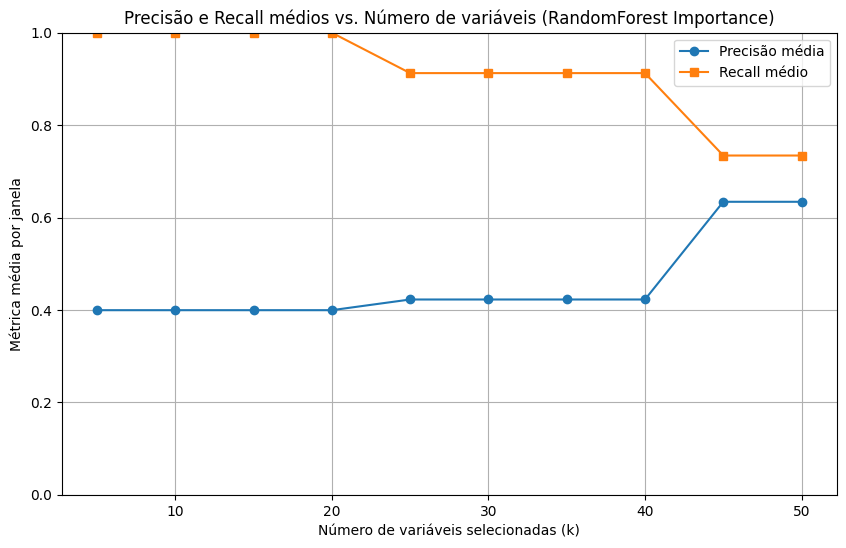

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, coeficientes)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [ ]:
n_features = 45
lista_colunas_selecionadas = coeficientes.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_ult_vs_mm_janela',
 'macd_cruzou_sinal_para_cima',
 'rsi_sobrevendido_30',
 'macd_acima_sinal',
 'volume_mean',
 'retorno_medio_neg',
 'retorno_desde_mudanca_ibov',
 'tr_pct_ultimo',
 'atr_pct_ultimo',
 'tr_pct_std',
 'alpha_papel_vs_ibov_mean',
 'retorno_desde_mudanca_close',
 'retorno_mean',
 'retorno_medio_pos',
 'retorno_std',
 'retorno_desde_mudanca_dolar',
 'correl_papel_ibov',
 'dolar_trend',
 'close_trend',
 'volume_ult_vs_mean',
 'volume_trend',
 'volume_std',
 'dolar_std',
 'tr_std',
 'ipca_ultimo',
 'rsi_sobrecomprado_70',
 'tr_ultimo',
 'tr_std_norm_atr',
 'atr_ultimo',
 'tr_mean',
 'atr_mean',
 'beta_papel_ibov',
 'dias_alta_pct',
 'close_dist_min',
 'dolar_ultimo',
 'selic_ultimo',
 'close_amplitude_norm_atr',
 'close_max',
 'rsi_ultimo',
 'rsi_mean',
 'ibov_amplitude',
 'ibov_trend']

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )

modelo_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.614
AUC na validação: 0.809
Diferença AUC (Treino - Validação): -0.194


(np.float64(0.6143047898756531),
 np.float64(0.808655738030058),
 np.float64(-0.1943509481544049))

Avaliar e logar modelo
MLflow Run ID: 4f9785b5b5b848ca8a9449b05a121fdb para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.592
AUC na validação: 0.690

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.614
  Precisão média (em 475 janelas com previsão positiva): 0.266
  Recall médio: 0.637

Threshold Ideal Selecionado: 0.56
  Precisão Média Esperada: 37.79%
  Recall Médio Esperado: 40.37%
  Janelas Usadas para Precisão: 413.0

Threshold ideal baseado em recall mínimo: 0.56

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.348
Recall médio: 0.384
Sinais de compra presentes na vallidação: 29.0
Sinais de compra previstos na validação: 19
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run 4f9785b5b5b848ca8a9449b05a121fdb


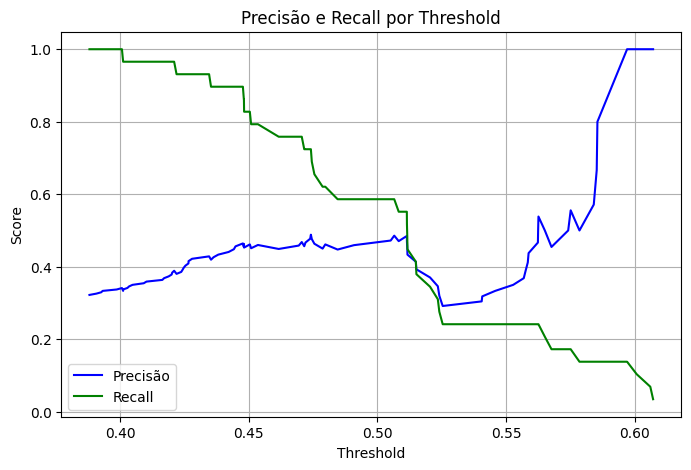

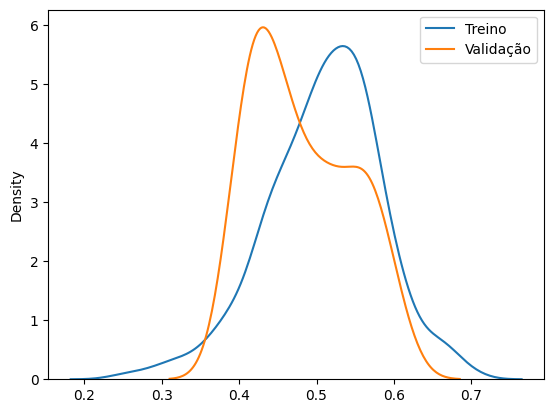

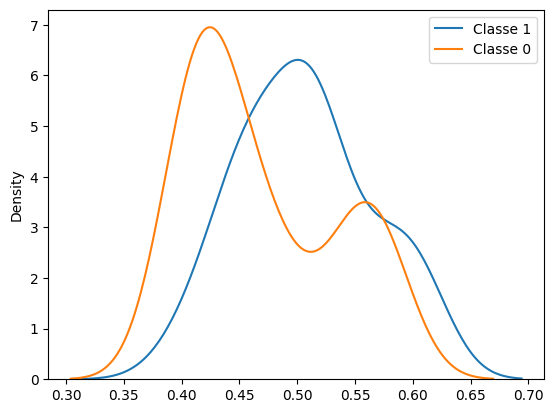

In [29]:
recall_minimo = 0.2
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

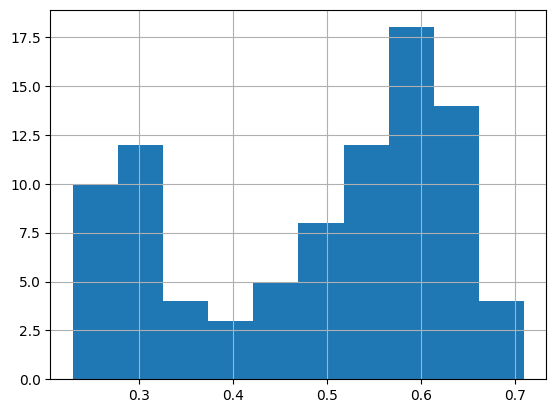

In [24]:
pd.Series(probas).hist()